In [1]:
print("Let's Start")

Let's Start


In [12]:
from sklearn.datasets import make_blobs
centroids = [(-5,-5) , (5,5)]
cluster_std = [1,1]
x , y = make_blobs(n_samples=500 , cluster_std=cluster_std , centers=centroids , n_features=2,random_state=2  )

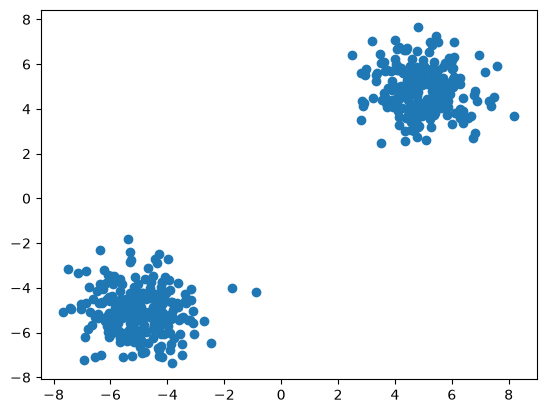

In [14]:
import matplotlib.pyplot as plt

plt.scatter(x[:,0] , x[:,1])
plt.show()

In [126]:
import random 
import numpy as np
class MYKmeans:

    def __init__(self , n_clusters = 2 , max_iters =100):
        self.n_clusters = n_clusters
        self.max_iters= max_iters
        self.centroids= None

    def fit(self , x):
        clusters = self.n_clusters
        random_point1 =random.randint(0 , x.shape[0]-1)
        random_point2 =random.randint(0 , x.shape[0]-1)
        random_points = (random_point1 , random_point2)
        self.centroids = x[random_points , :]
        for i in range(self.max_iters):
            #assign cluster_std

            centroids_groups = self.assign_clusters(x)
            old_centroids = self.centroids
            #move centroids
            self.centroids = self.move_centroids(x , centroids_groups)
            #check situation
            if (self.centroids == old_centroids).all():
                break

        return centroids_groups
            
    def assign_clusters(self ,x):
        clusters = []
        distances = []
        for row in x:
            for center in self.centroids:
                dis = np.sqrt(np.dot(row-center , row-center))
                distances.append(dis)
            min_dis = min(distances)
            index = distances.index(min_dis)
            clusters.append(index)
            distances.clear()

        return np.array(clusters)


    def move_centroids(self, x , centroid_groups):
        new_centroids = []
        unique = np.unique(centroid_groups)
        for type in unique:
            new_centroids.append(x[centroid_groups==type].mean(axis=0))

        return np.array(new_centroids)
        
        



In [127]:
my = MYKmeans()
y_means = my.fit(x)

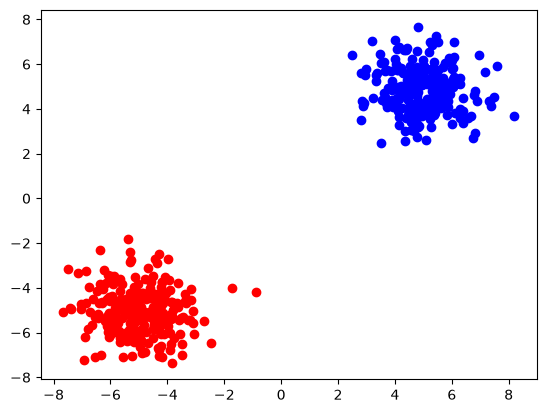

In [128]:
plt.scatter(x[y_means == 0,0] , x[y_means==0,1] , color = 'red')
plt.scatter(x[y_means == 1,0] , x[y_means==1,1] , color = 'blue')

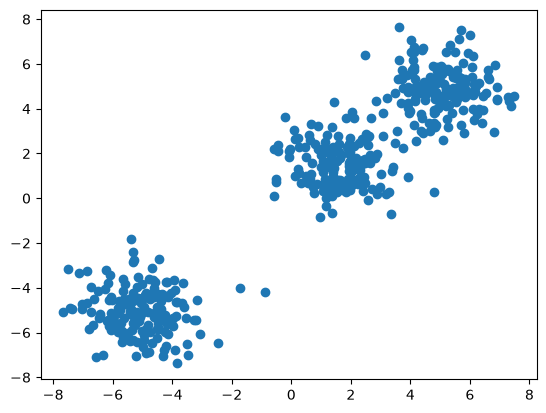

In [141]:
from sklearn.datasets import make_blobs
centroids = [(-5,-5) , (5,5) , (1.6,1.6)]
cluster_std = [1,1,1]
x2 , y2 = make_blobs(n_samples=500 , cluster_std=cluster_std , centers=centroids , n_features=2,random_state=2  )
import matplotlib.pyplot as plt

plt.scatter(x2[:,0] , x2[:,1])
plt.show()

In [142]:
my2 = MYKmeans(n_clusters=3)
y_means = my2.fit(x2)

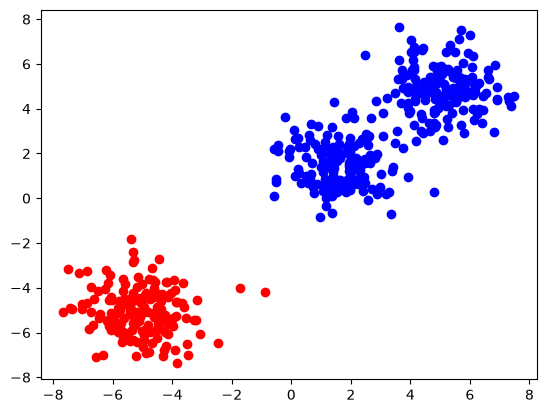

In [143]:
plt.scatter(x2[y_means == 0,0] , x2[y_means==0,1] , color = 'red')
plt.scatter(x2[y_means == 1,0] , x2[y_means==1,1] , color = 'blue')
plt.scatter(x2[y_means == 2,0] , x2[y_means==2,1] , color = 'green')